
# LAB: **IMAGE SEGMENTATION**



---

***STUDENT(S):*** 

---


**Image segmentation** is a method in which a digital image is broken down into various subgroups called *Image segments* which helps in reducing the complexity of the image to make further processing or analysis of the image simpler. **Segmentation in easy words is assigning labels to pixels.** All picture elements or pixels belonging to the same category have a common label assigned to them. **For example**: Let’s take a problem where the picture has to be provided as input for object detection. Rather than processing the whole image, the detector can be inputted with a region selected by a segmentation algorithm. This will prevent the detector from processing the whole image thereby reducing inference time.
<figure>
<center><img src="https://vladlen.info/wp-content/uploads/FSO-1.jpg" width="60%"></center> 
<figcaption align = "center"> Image segmentation example. </figcaption>
</figure>


# Approaches in Image Segmentation

*   *Similarity approach*: This approach is based on detecting similarity between image pixels to form a segment, based on a threshold. ML algorithms like clustering are based on this type of approach to segment an image.
*   *Discontinuity approach*: This approach relies on the discontinuity of pixel intensity values of the image. Line, Point, and Edge Detection techniques use this type of approach for obtaining intermediate segmentation results which can be later processed to obtain the final segmented image.

# Image Segmentation Techniques

*   Threshold Based Segmentation
*   Edge Based Segmentation
*   Region-Based Segmentation
*   Clustering Based Segmentation
*   **Artificial Neural Network Based Segmentation**

In this lab we will focus on **Artificial Neural Network Based Segmentation** using **U-Net architecture**.

# U-Net

U-Net, named for its U-shape, was originally created in 2015 for tumor detection, but in the years since has become a very popular choice for other **semantic segmentation tasks**.

U-Net builds on a previous architecture called the **Fully Convolutional Network (FCN)** which replaces the dense layers found in a typical CNN with a transposed convolution layer that upsamples the feature map back to the size of the original input image, while preserving the spatial information. This is necessary because the dense layers destroy spatial information (the "where" of the image), which is an essential part of image segmentation tasks. An added bonus of using transpose convolutions is that **the input size no longer needs to be fixed**, as it does when dense layers are used.

Unfortunately, **the final feature layer of the FCN suffers from information loss due to downsampling too much**. It then becomes difficult to upsample after so much information has been lost, causing an output that looks rough.

<figure>
<center><img src="https://miro.medium.com/max/640/1*NXNGhfSyzQcKzoOSt-Z0Ng.webp" width="60%"></center> 
<figcaption align = "center"> FCN architecture. </figcaption>
</figure>


**U-Net improves on the FCN**. Instead of one transposed convolution at the end of the network, it uses a matching number of convolutions for downsampling the input image to a feature map, and transposed convolutions for upsampling those maps back up to the original input image size. It also adds **skip connections**, to retain information that would otherwise become lost during encoding. Skip connections send information to every upsampling layer in the decoder from the corresponding downsampling layer in the encoder, capturing finer information while also keeping computation low. These help prevent information loss, as well as model overfitting.

<figure>
<center><img src="https://lmb.informatik.uni-freiburg.de/people/ronneber/u-net/u-net-architecture.png" width="70%"></center> 
<figcaption align = "center"> U-Net architecture. </figcaption>
</figure>






# Dataset

In this lab we will use [**Cityscapes**](https://www.cityscapes-dataset.com/) **Image Pairs dataset**. It contains labeled videos taken from vehicles driven in Germany. This version is a processed subsample created as part of the [Pix2Pix](https://phillipi.github.io/pix2pix/) paper. The dataset has still images from the original videos, and the semantic segmentation labels are shown in images alongside the original image. This is one of the best datasets around for semantic segmentation tasks.

This dataset has 2975 training images files and 500 validation image files. Each image file is 256x512 pixels, and each file is a composite with the original photo on the left half of the image, alongside the labeled image (output of semantic segmentation) on the right half.



# Imports


In [1]:
import os
from PIL import Image
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

import torch
import torchvision
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader


from tqdm.notebook import tqdm

%matplotlib inline
%config InlineBackend.figure_format = 'retina'  #To get figures with high quality!

# Reproducibility
torch.manual_seed(0)
np.random.seed(0)

print('PyTorch:', torch.__version__, '| CUDA available:', torch.cuda.is_available())

PyTorch: 2.14.1+cu126 | CUDA available: True


# PART I: Loading Cityscapes dataset

First, import to your own Drive the folder I shared with you in Aula Global.

In [2]:
# Running locally (not in Colab): no need to mount Google Drive.
# from google.colab import drive
# drive.mount('/content/drive')

In [3]:
# UPDATE THIS ACCORDING TO YOUR PATH!
# Local copy of Cityscapes.zip extracted on drive D:
path_to_folder = 'D:/dl_lab02/data/Cityscapes/cityscapes_data/'

train_dir = os.path.join(path_to_folder, "train")
test_dir = os.path.join(path_to_folder, "val")

train_fns = os.listdir(train_dir)
test_fns = os.listdir(test_dir)

print('We have %d train images.' %len(train_fns))
print('We have %d test images.' %len(test_fns))

We have 2975 train images.
We have 500 test images.


Visualize one image from Cityscapes

D:/dl_lab02/data/Cityscapes/cityscapes_data/train\1.jpg


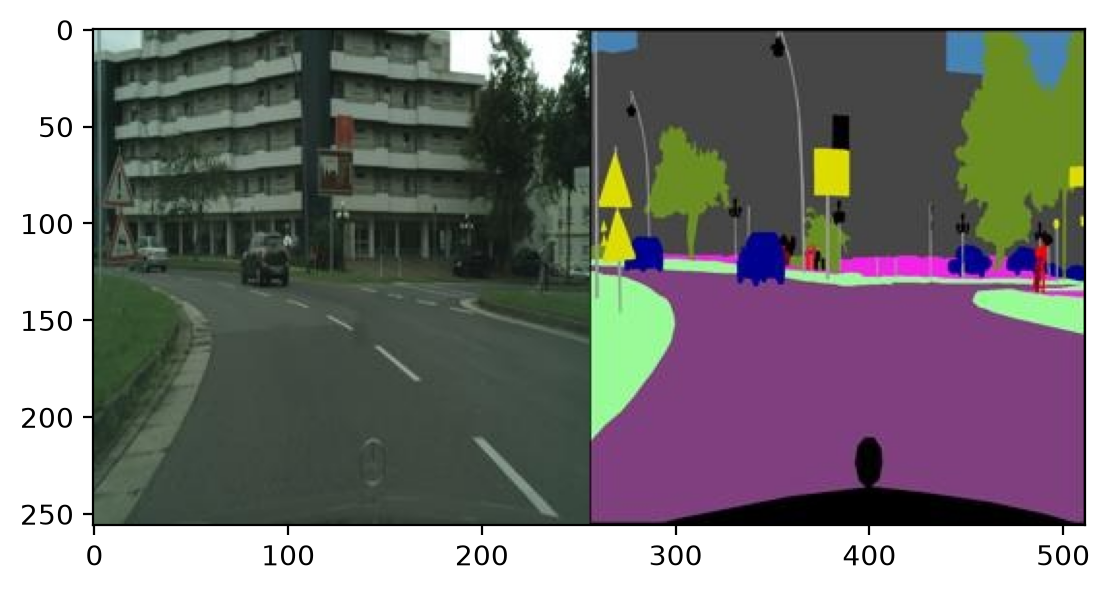

In [4]:
sample_image_fp = os.path.join(train_dir, train_fns[0])
sample_image = Image.open(sample_image_fp).convert("RGB")
plt.imshow(sample_image)
print(sample_image_fp)

# PART II: Extracting Image and Labels
The input images contain both the road scene and the corresponding label in the same image. Thus, we are splitting it and presenting it as two separate entities.

In [5]:
def split_image(image):
  image = np.array(image)
  cityscape, label = image[:, :256, :], image[:, 256:, :]
  return cityscape, label

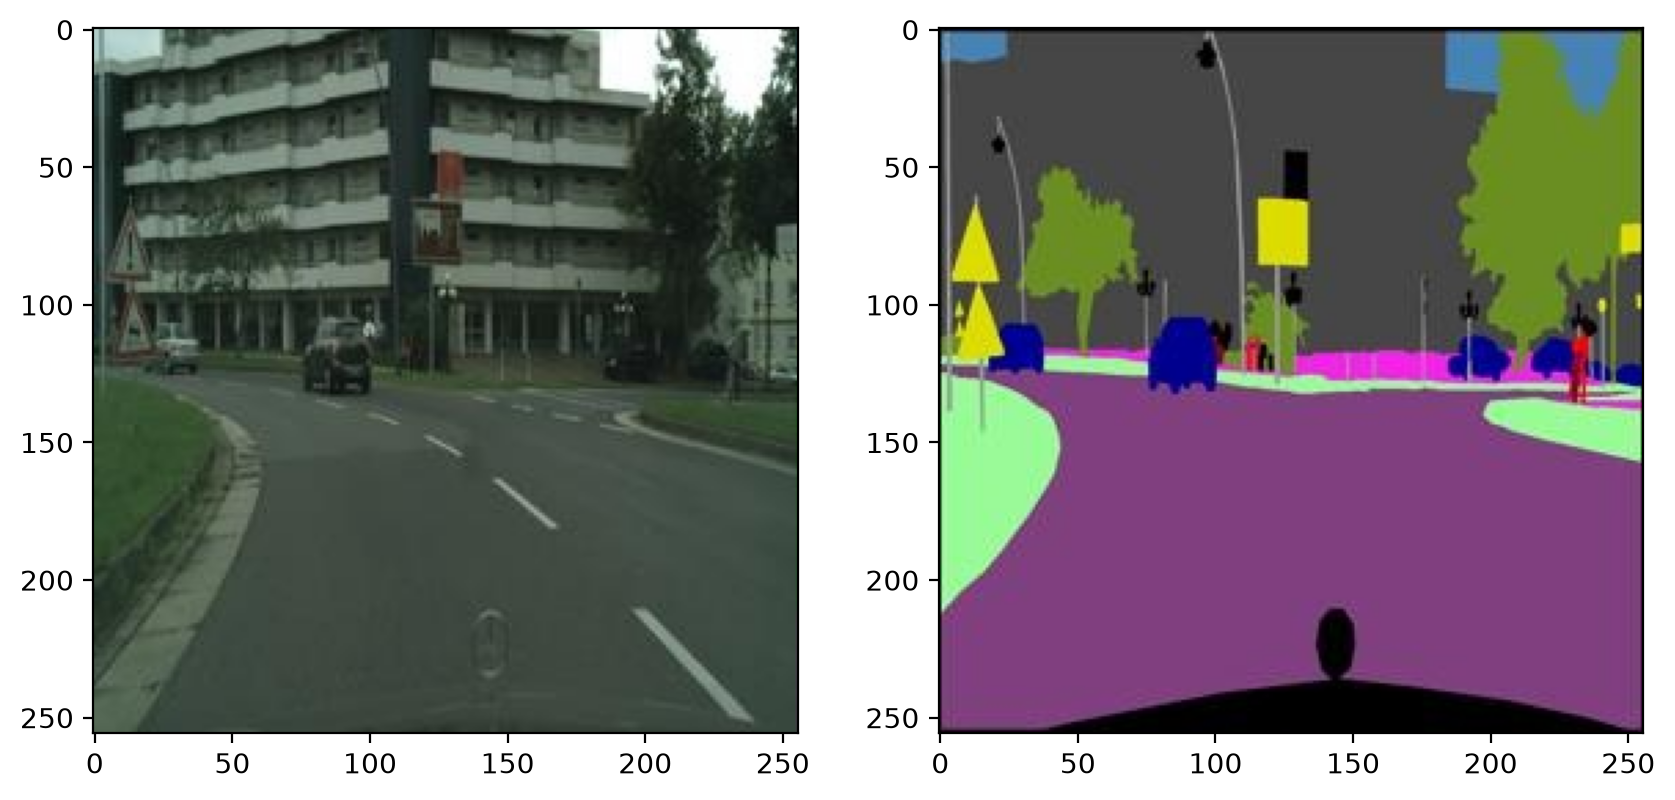

In [6]:
sample_image = np.array(sample_image)
cityscape, label = split_image(sample_image)

# display split images
cityscape, label = Image.fromarray(cityscape), Image.fromarray(label)
fig, axes = plt.subplots(1, 2, figsize=(10,5))
axes[0].imshow(cityscape)
axes[1].imshow(label)

We need to transform the RGB label image (3 channels) to a label matrix (1 channel). For this, we have two options:

1.   Define a dictionary that maps RGB values to class labels.
2.   Train a clustering model (as K-Means) to assign class labels to RGB values automatically.


Let's try the second option to spice up things a little!

> **Exercise**: Complete the following code.


In [7]:
# Define random RGB images
num_items = 5000
color_array = np.random.choice(range(256), 3*num_items).reshape(-1,3)
print(color_array.shape)

(5000, 3)


In [8]:
# Learn how to cluster all the colors in num_classes
num_classes = 10
label_model = KMeans(n_clusters=num_classes, n_init=10, random_state=0)
label_model.fit(color_array)

,"n_clusters n_clusters: int, default=8The number of clusters to form as well as the number ofcentroids to generate.For an example of how to choose an optimal value for `n_clusters` refer to:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_silhouette_analysis.py`.",10
,"n_init n_init: 'auto' or int, default='auto'Number of times the k-means algorithm is run with different centroidseeds. The final results is the best output of `n_init` consecutive runsin terms of inertia. Several runs are recommended for sparsehigh-dimensional problems (see :ref:`kmeans_sparse_high_dim`).When `n_init='auto'`, the number of runs depends on the value of init:10 if using `init='random'` or `init` is a callable;1 if using `init='k-means++'` or `init` is an array-like... versionadded:: 1.2 Added 'auto' option for `n_init`... versionchanged:: 1.4 Default value for `n_init` changed to `'auto'`.",10
,"random_state random_state: int, RandomState instance or None, default=NoneDetermines random number generation for centroid initialization. Usean int to make the randomness deterministic.See :term:`Glossary <random_state>`.",0
,"init init: {'k-means++', 'random'}, callable or array-like of shape (n_clusters, n_features), default='k-means++'Method for initialization:* 'k-means++' : selects initial cluster centroids using sampling based on an empirical probability distribution of the points' contribution to the overall inertia. This technique speeds up convergence. The algorithm implemented is ""greedy k-means++"". It differs from the vanilla k-means++ by making several trials at each sampling step and choosing the best centroid among them.* 'random': choose `n_clusters` observations (rows) at random from data for the initial centroids.* If an array is passed, it should be of shape (n_clusters, n_features) and gives the initial centers.* If a callable is passed, it should take arguments X, n_clusters and a random state and return an initialization.For an example of how to use the different `init` strategies, see:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_digits.py`.For an evaluation of the impact of initialization, see the example:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_stability_low_dim_dense.py`.",'k-means++'
,"max_iter max_iter: int, default=300Maximum number of iterations of the k-means algorithm for asingle run.",300
,"tol tol: float, default=1e-4Relative tolerance with regards to Frobenius norm of the differencein the cluster centers of two consecutive iterations to declareconvergence.",0.0001
,"verbose verbose: int, default=0Verbosity mode.",0
,"copy_x copy_x: bool, default=TrueWhen pre-computing distances it is more numerically accurate to centerthe data first. If copy_x is True (default), then the original data isnot modified. If False, the original data is modified, and put backbefore the function returns, but small numerical differences may beintroduced by subtracting and then adding the data mean. Note that ifthe original data is not C-contiguous, a copy will be made even ifcopy_x is False. If the original data is sparse, but not in CSR format,a copy will be made even if copy_x is False.",True
,"algorithm algorithm: {""lloyd"", ""elkan""}, default=""lloyd""K-means algorithm to use. The classical EM-style algorithm is `""lloyd""`.The `""elkan""` variation can be more efficient on some datasets withwell-defined clusters, by using the triangle inequality. However it'smore memory intensive due to the allocation of an extra array of shape`(n_samples, n_clusters)`... versionchanged:: 0.18 Added Elkan algorithm.. versionchanged:: 1.1 Renamed ""full"" to ""lloyd"", and deprecated ""auto"" and ""full"". Changed ""auto"" to use ""lloyd"" instead of ""elkan"".",'lloyd'
Name,Type,Value
"cluster_centers_ cluster_centers_: ndarray of shape (n_clusters, n_features)Coordinates of cluster centers. If the algorithm stops before fullyconverging (see ``tol`` and ``max_iter``), these will not beconsistent with ``labels_``.","ndarray[float64](10, 3)","[[ 4

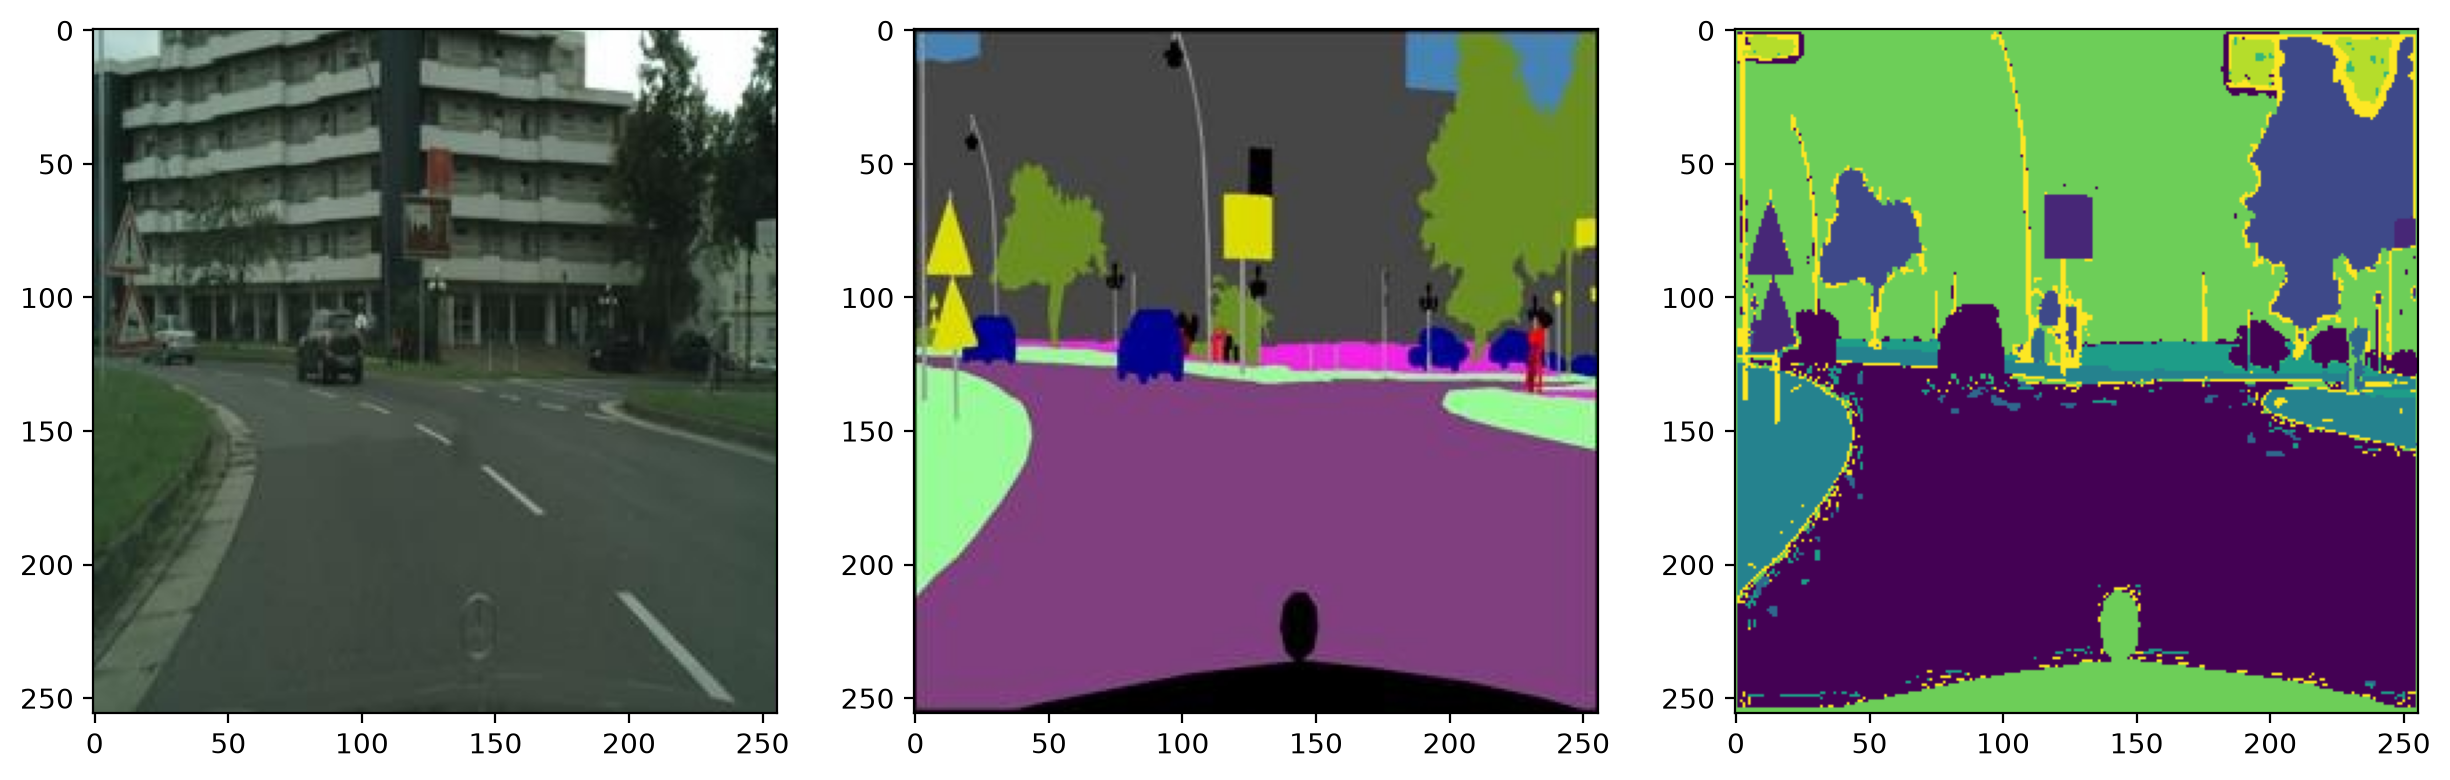

In [9]:
cityscape, label = split_image(sample_image)
label_class = label_model.predict(label.reshape(-1,3)).reshape(256,256)
fig, axes = plt.subplots(1,3,figsize=(15,5))
axes[0].imshow(cityscape)
axes[1].imshow(label)
axes[2].imshow(label_class)

The K-Means model is trained on 5000 **random** RGB colors, so its 10 clusters split the RGB cube into 10 regions of similar colors. Each color of the label image is assigned to the closest centroid. This means that the resulting classes are not exactly the Cityscapes semantic classes: label colors that are close in RGB space (e.g. several dark or greyish classes) end up in the same cluster, and the anti-aliased borders between regions may fall into a third cluster. Even so, the main structures of the scene (road, sidewalk, vegetation, buildings/sky, cars...) are recovered as different classes, which is good enough for this lab.

Now we define a Dataset for this data. In the transformations we reduce the size of the images to speed up training.

In [10]:
class CityscapeDataset(Dataset):

  def __init__(self, image_dir, label_model):

    self.image_dir = image_dir
    self.image_fns = os.listdir(image_dir)
    self.label_model = label_model

  def __len__(self):
    return len(self.image_fns)
  
  def __getitem__(self, index):

    # Get the image from the root directory
    image_fn = self.image_fns[index]
    image_fp = os.path.join(self.image_dir, image_fn)
    image = Image.open(image_fp).convert("RGB")
    image = np.array(image)

    # Split in image and labels
    cityscape, label = self.split_image(image)

    # Extract and transform label matrix
    label = np.array(self.transform_lab(Image.fromarray(label)))
    label_class = self.label_model.predict(label.reshape(-1,3)).reshape(64,64)
    label_class = torch.Tensor(label_class).long()

    # Transform image
    cityscape = self.transform_img(Image.fromarray(cityscape))

    return cityscape, label_class

  def split_image(self, image):

    image = np.array(image)
    cityscape, label = image[:, :256, :], image[:, 256:, :]

    return cityscape, label
  
  def transform_img(self, image):

    transform_ops = torchvision.transforms.Compose([
                                        torchvision.transforms.Resize((64, 64)),
                                        torchvision.transforms.ToTensor(),
                                        torchvision.transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
    ])

    return transform_ops(image)

  def transform_lab(self, image):

    transform_ops = torchvision.transforms.Compose([
                                        torchvision.transforms.Resize((64, 64))
    ])

    return transform_ops(image)

> **Exercise**: complete the following code to create a dataset for training data and another one for test data. Show an example (image and its segmentation) from the train dataset.

In [11]:
dataset_train = CityscapeDataset(train_dir, label_model)
dataset_test = CityscapeDataset(test_dir, label_model)

print('Train dataset: ', len(dataset_train))
print('Test dataset: ', len(dataset_test))

Train dataset:  2975
Test dataset:  500


Let's show an example from our defined dataset. We define a method to visualize the images, as they are normalized.

In [12]:
def img_show(img):
    img = img / 2 + 0.5     # unnormalize to plot
    npimg = img.numpy()
    plt.imshow(np.transpose(npimg, (1, 2, 0)))
    plt.show()

Image shape:  torch.Size([3, 64, 64]) | Label shape:  torch.Size([64, 64]) | Classes present:  [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]


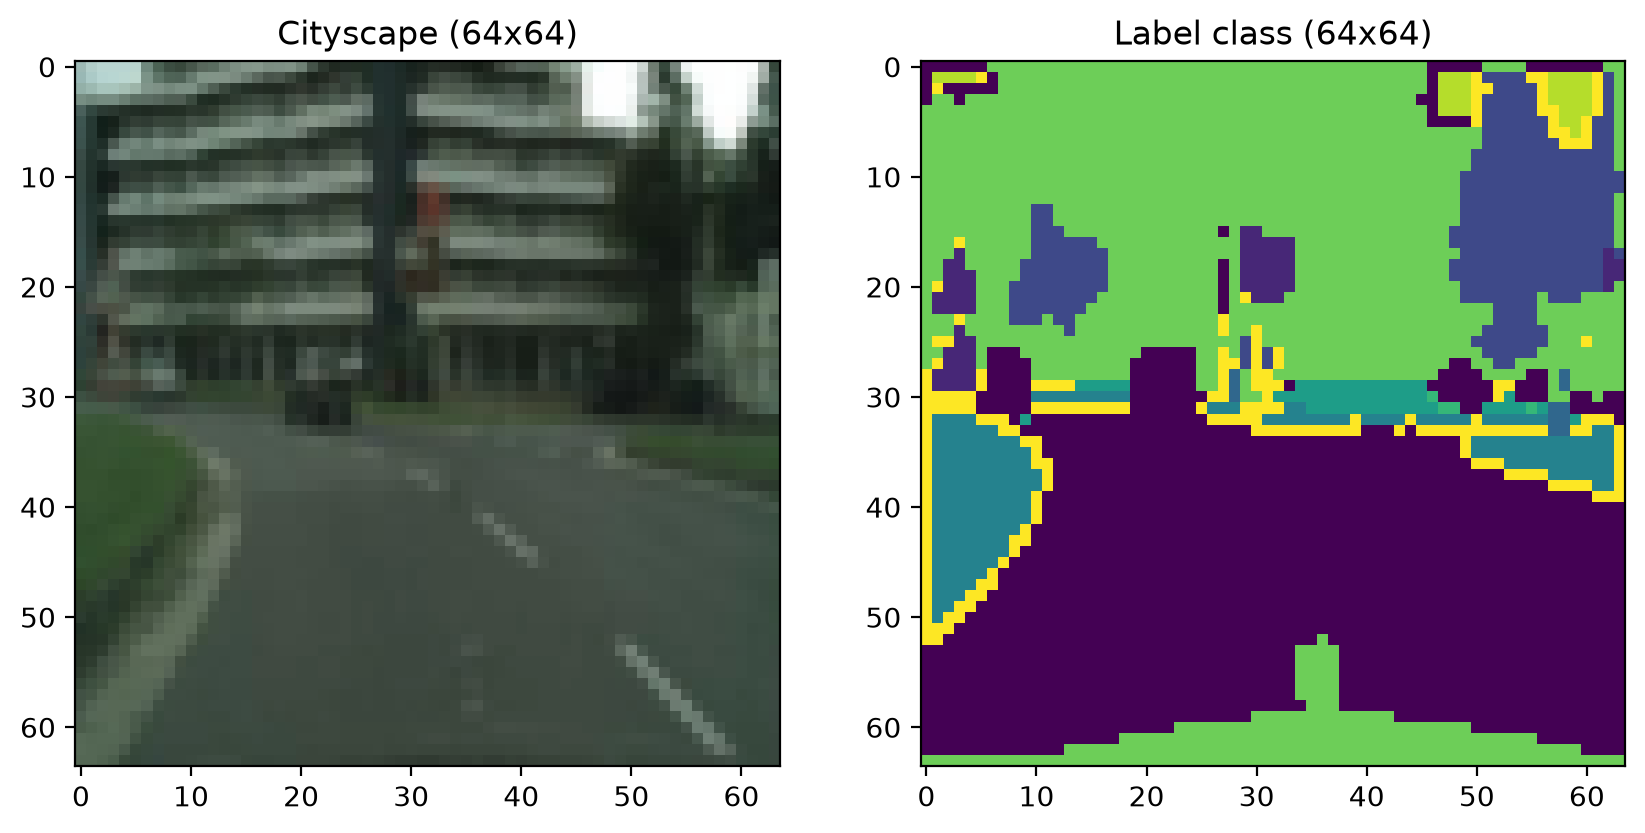

In [13]:
# Example (image and its segmentation) from the train dataset
img, label_class = dataset_train[0]
print('Image shape: ', img.shape, '| Label shape: ', label_class.shape, '| Classes present: ', label_class.unique().tolist())

fig, axes = plt.subplots(1, 2, figsize=(10, 5))
axes[0].imshow(np.transpose((img / 2 + 0.5).numpy(), (1, 2, 0)))
axes[0].set_title('Cityscape (64x64)')
axes[1].imshow(label_class.numpy(), vmin=0, vmax=num_classes-1)
axes[1].set_title('Label class (64x64)')
plt.show()


One we have defined the Dataset, we can define train and test dataloaders!

In [14]:
batch_size = 32
valid_size = 500

# Training partition
part_tr = torch.utils.data.random_split(dataset_train, [len(dataset_train)-valid_size, valid_size])[0]
# Use sampler for randomization
training_sampler = torch.utils.data.SubsetRandomSampler(range(len(part_tr)))
# Define the dataloader
trainloader = torch.utils.data.DataLoader(part_tr, batch_size=batch_size, sampler=training_sampler)

# Validation partition
part_val = torch.utils.data.random_split(dataset_train, [valid_size, len(dataset_train)-valid_size])[0]
# Use sampler for randomization
valid_sampler = torch.utils.data.SubsetRandomSampler(range(len(part_val)))
# Define the dataloader
validloader = torch.utils.data.DataLoader(part_val, batch_size=batch_size, sampler=valid_sampler)

# Test partition
# Use sampler for randomization
test_sampler = torch.utils.data.SubsetRandomSampler(range(len(dataset_test)))
# Define the dataloader
testloader = torch.utils.data.DataLoader(dataset_test, batch_size=batch_size, sampler=test_sampler)


In [15]:
print('TRAIN: ', len(part_tr))
print('VALIDATION: ', len(part_val))
print('TEST: ', len(dataset_test))


TRAIN:  2475
VALIDATION:  500
TEST:  500


# PART III: Define the model

In this lab we are reproducing the following architecture, but for color images (we have a 3 channel image as input).

<figure>
<center><img src="https://lmb.informatik.uni-freiburg.de/people/ronneber/u-net/u-net-architecture.png" width="70%"></center> 
<figcaption align = "center"> U-Net architecture. </figcaption>
</figure>


This architecture has 4 main blocks:

*   **Encoder**: The contracting path follows the typical architecture of a convolutional network. It consists of the repeated application of two 3×3 convolutions (padding=1, stride=1), each followed by a rectified linear unit (ReLU) and a 2×2 max pooling operation with stride 2 for downsampling. At each downsampling step we double the number of feature channels.
*   **Bottleneck**: Mid layer that passes the compressed information from the encoder to the decoder.
*   **Decoder**: Every step in the expansive path consists of an upsampling of the feature map followed by a 2×2 convolution (“up-convolution”) (stride = 2, padding = 0) that halves the number of feature channels, a concatenation with the correspondingly cropped feature map from the contracting path, and two 3×3 convolutions, each followed by a ReLU.
*   **Classifier**: Final convolution layer that outputs the segmented image.

The original U-Net does not use batch normalization in between the convolution layer and ReLU. Here we insert batch normalization in between them. It helps the network to reduce internal covariance shift and makes the network more stable while training.



# Basic blocks
First we implement the basic blocks for this architecture. The first one is the **convolutional block**, which consists of two 3x3 convolutional layers (padding=1, stride=1), each one followed by batch normalization and ReLU activation.

> **Exercise**: complete the following code.

In [16]:
# === CONVOLUTIONAL BLOCK === #
# Two 3x3 convolutional layers, each followed by a batch
# normalization and a ReLU activation.

class conv_block(nn.Module):
    def __init__(self, in_c, out_c):
        super().__init__()

        self.conv1 = nn.Conv2d(in_c, out_c, kernel_size=3, padding=1, stride=1)
        self.bn1 = nn.BatchNorm2d(out_c)

        self.conv2 = nn.Conv2d(out_c, out_c, kernel_size=3, padding=1, stride=1)
        self.bn2 = nn.BatchNorm2d(out_c)

        self.relu = nn.ReLU()

    def forward(self, inputs):

        x = self.conv1(inputs)
        x = self.bn1(x)
        x = self.relu(x)

        x = self.conv2(x)
        x = self.bn2(x)
        x = self.relu(x)

        return x

Now we define the **encoder block**, which consists of a convolutional block followed by a 2×2 max pooling operation with stride 2 for downsampling. At each downsampling step we double the number of feature channels. 

Note that this block should return the output before and after the downsampling, so we can esily implement the skip connections in the full architecture.

> **Exercise**: complete the following code.

In [17]:
# === ENCODER BLOCK === #
# It consists of an conv_block followed by a max pooling.
# Here the number of filters doubles and the height and width half after every block.

class encoder_block(nn.Module):
    def __init__(self, in_c, out_c):
        super().__init__()

        self.conv = conv_block(in_c, out_c)
        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)

    def forward(self, inputs):

        x = self.conv(inputs)   # output before downsampling (skip connection)
        p = self.pool(x)        # output after downsampling

        return x, p

The last basic block we need to implement is the decoder block, which consists of a a 2×2 transpose convolution (“up-convolution”) (stride = 2, padding = 0) that halves the number of feature channels, a concatenation with the correspondingly cropped feature map from the contracting path (**skip connections!**), and a convolutional block.

> **Exercise**: complete the following code.

In [18]:
# === DECODER BLOCK === #
# The decoder block begins with a transpose convolution, followed by a concatenation with the skip
# connection from the encoder block. Next comes the conv_block.
# Here the number filters decreases by half and the height and width doubles.

class decoder_block(nn.Module):
    def __init__(self, in_c, out_c):
        super().__init__()

        self.up = nn.ConvTranspose2d(in_c, out_c, kernel_size=2, stride=2, padding=0)
        self.conv = conv_block(out_c + out_c, out_c)   # after concatenation with the skip

    def forward(self, inputs, skip):
        x = self.up(inputs)
        x = torch.cat([x, skip], axis=1)
        x = self.conv(x)

        return x

# Full architecture

Now that we have implemented all the basic blocks, we can build our **full U-Net architecture**! 

> **Exercise**: complete the following code.

In [19]:
# === FULL ARCHITECTURE === #

class UNet(nn.Module):
    def __init__(self, n_labels):
        super().__init__()

        # ENCODER #
        # in_channels = 3, out_channels=64 for the first block
        self.e1 = encoder_block(3, 64)
        self.e2 = encoder_block(64, 128)
        self.e3 = encoder_block(128, 256)
        self.e4 = encoder_block(256, 512)

        # BOTTLENECK #
        self.b = conv_block(512, 1024)

        # DECODER #
        self.d1 = decoder_block(1024, 512)
        self.d2 = decoder_block(512, 256)
        self.d3 = decoder_block(256, 128)
        self.d4 = decoder_block(128, 64)

        # CLASSIFIER #
        self.outputs = nn.Conv2d(64, n_labels, kernel_size=1, padding=0)

    def forward(self, inputs):

        # NOTATION:
        # s -> skip
        # p -> pooling

        # ENCODER #
        s1, p1 = self.e1(inputs)   # 64   x 64x64 -> 32x32
        s2, p2 = self.e2(p1)       # 128  x 32x32 -> 16x16
        s3, p3 = self.e3(p2)       # 256  x 16x16 -> 8x8
        s4, p4 = self.e4(p3)       # 512  x 8x8   -> 4x4

        # BOTTLENECK #
        b = self.b(p4)             # 1024 x 4x4

        # DECODER #
        d1 = self.d1(b, s4)        # 512  x 8x8
        d2 = self.d2(d1, s3)       # 256  x 16x16
        d3 = self.d3(d2, s2)       # 128  x 32x32
        d4 = self.d4(d3, s1)       # 64   x 64x64

        # CLASSIFIER #
        outputs = self.outputs(d4)

        return outputs

The following class completes the implementation of the U-Net, extending it with a training method.

> **Exercise**: complete the following code.

In [20]:
class UNet_extended(UNet):

    def __init__(self, n_labels, lr=1e-3,epochs=20):

        super().__init__(n_labels)

        # TRAINING VARIABLES
        self.lr = lr
        self.optim = optim.Adam(self.parameters(), self.lr)
        self.epochs = epochs

        # CRITERION
        self.criterion = nn.CrossEntropyLoss()   # pixel-wise multiclass classification (logits)

        # LOSS EVOLUTION
        self.loss_during_training = []
        self.valid_loss_during_training = []

        self.device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
        self.to(self.device)

    def trainloop(self, trainloader, validloader):

        for e in range(int(self.epochs)):

          self.train()

          running_loss = 0.

          for images, labels in trainloader:

            images = images.to(self.device)
            labels = labels.to(self.device)

            self.optim.zero_grad()

            pred = self.forward(images)

            loss = self.criterion(pred, labels)

            loss.backward()

            self.optim.step()

            running_loss += loss.item()

          self.loss_during_training.append(running_loss/len(trainloader))

          # Validation
          # Turn off gradients for validation, saves memory and computations
          self.eval()   # BatchNorm in inference mode
          with torch.no_grad():

              running_loss = 0.

              for images,labels in validloader:

                  images = images.to(self.device)
                  labels = labels.to(self.device)

                  pred = self.forward(images)

                  loss = self.criterion(pred, labels)

                  running_loss += loss.item()

              self.valid_loss_during_training.append(running_loss/len(validloader))

          print('\nTrain Epoch: {} -> Training Loss: {:.6f}'.format(e,self.loss_during_training[-1]))
          print('Train Epoch: {} -> Validation Loss: {:.6f}'.format(e,self.valid_loss_during_training[-1]))

    def eval_performance(self,dataloader):

        loss = 0
        accuracy = 0

        self.eval()
        # Turn off gradients for validation, saves memory and computations
        with torch.no_grad():

            for images,labels in dataloader:
                # Move input and label tensors to the default device
                images, labels = images.to(self.device), labels.to(self.device)
                probs = self.forward(images)

                labels_pred = torch.argmax(probs, dim=1)
                equals = (labels_pred == labels)
                accuracy += torch.mean(equals.type(torch.FloatTensor))

            return accuracy/len(dataloader)

> **Exercise**: Train the model for 30 epochs. Plot the evolution of train and validation losses. Is the network overfitting?




Train Epoch: 0 -> Training Loss: 0.972827
Train Epoch: 0 -> Validation Loss: 0.760722



Train Epoch: 1 -> Training Loss: 0.666679
Train Epoch: 1 -> Validation Loss: 0.676973



Train Epoch: 2 -> Training Loss: 0.608482
Train Epoch: 2 -> Validation Loss: 0.648603



Train Epoch: 3 -> Training Loss: 0.568950
Train Epoch: 3 -> Validation Loss: 0.657532



Train Epoch: 4 -> Training Loss: 0.543471
Train Epoch: 4 -> Validation Loss: 0.562032



Train Epoch: 5 -> Training Loss: 0.515651
Train Epoch: 5 -> Validation Loss: 0.605373


... (20 outputs left out)


Train Epoch: 26 -> Training Loss: 0.315844
Train Epoch: 26 -> Validation Loss: 0.340579



Train Epoch: 27 -> Training Loss: 0.306269
Train Epoch: 27 -> Validation Loss: 0.386597



Train Epoch: 28 -> Training Loss: 0.293928
Train Epoch: 28 -> Validation Loss: 0.321270



Train Epoch: 29 -> Training Loss: 0.289886
Train Epoch: 29 -> Validation Loss: 0.316895


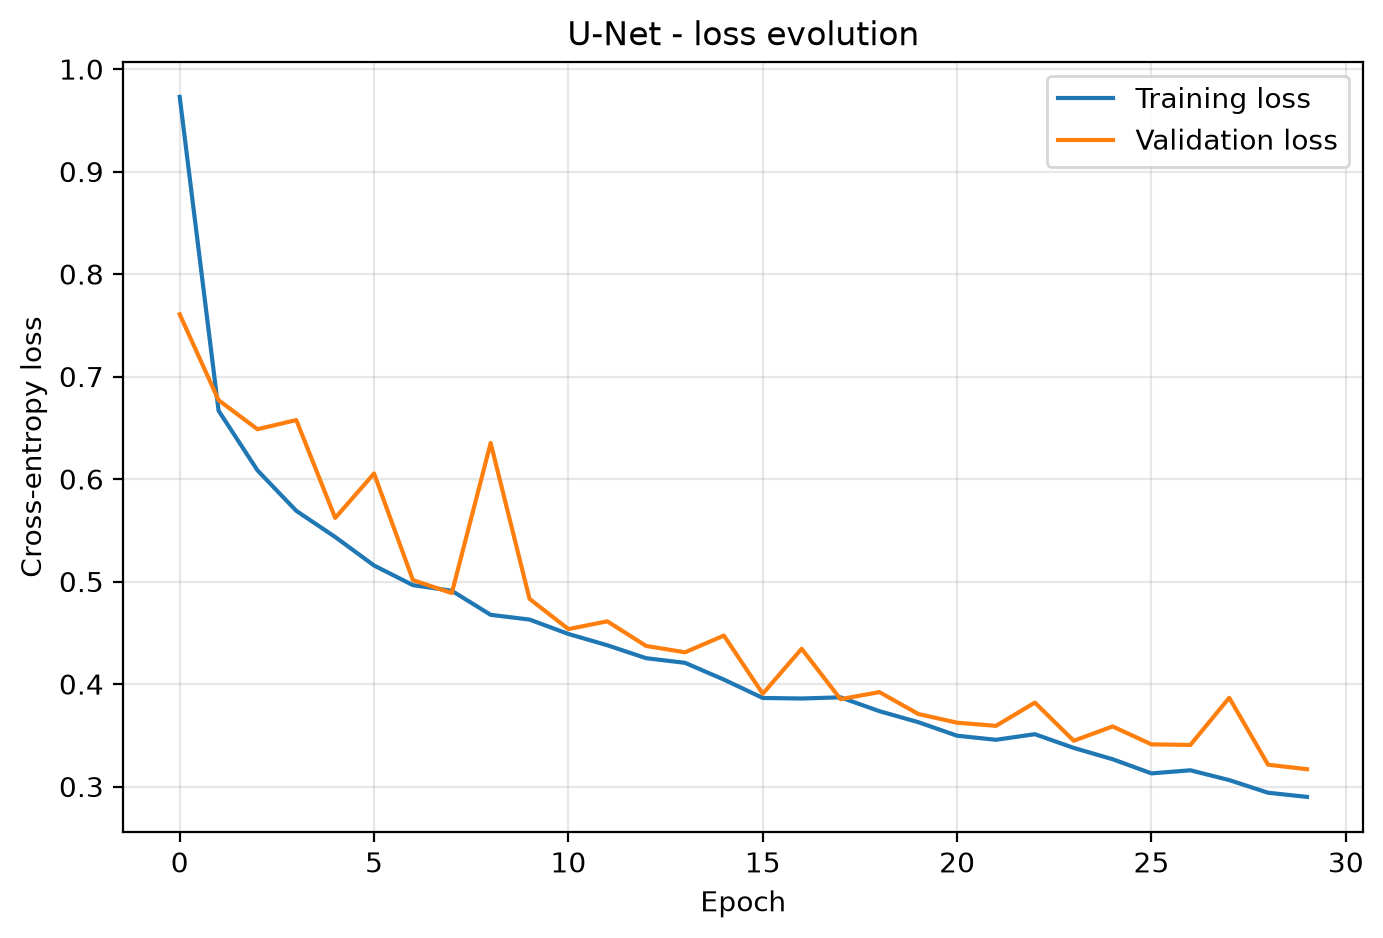

In [21]:
n_epochs = 30

my_unet = UNet_extended(n_labels=num_classes, lr=1e-3, epochs=n_epochs)
my_unet.trainloop(trainloader, validloader)

plt.figure(figsize=(8, 5))
plt.plot(my_unet.loss_during_training, label='Training loss')
plt.plot(my_unet.valid_loss_during_training, label='Validation loss')
plt.xlabel('Epoch')
plt.ylabel('Cross-entropy loss')
plt.title('U-Net - loss evolution')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

**Is the network overfitting?** No. The training loss decreases monotonically from ≈0.97 to ≈0.29, and the validation loss follows it very closely (from ≈0.76 to ≈0.32), with only a few isolated spikes (e.g. epochs 8 and 27) caused by the small validation set and by the noisy updates of Adam with a constant learning rate. The gap between both curves stays small during the whole training, and both are still going down at epoch 30. So, if anything, the model is still **underfitting slightly**: training for more epochs (or with a learning-rate schedule) would probably reduce both losses further.

> **Exercise**: Evaluate the performance of the model in the different data partitions.

In [22]:
acc_train = my_unet.eval_performance(trainloader)
acc_valid = my_unet.eval_performance(validloader)
acc_test = my_unet.eval_performance(testloader)

print('U-Net pixel accuracy')
print('  Train:      {:.4f}'.format(acc_train))
print('  Validation: {:.4f}'.format(acc_valid))
print('  Test:       {:.4f}'.format(acc_test))

U-Net pixel accuracy
  Train:      0.9031
  Validation: 0.8964
  Test:       0.8460


The U-Net reaches a pixel accuracy of **≈90.3 % in train, ≈89.6 % in validation and ≈84.6 % in test**.

* Train and validation are almost the same. However, the validation accuracy is optimistic: the training and validation partitions are obtained with two **independent** `random_split`s of `dataset_train`, so most of the 500 validation images were also used for training (only ~83 % of the images are in `part_tr`, so ~415 of the 500 validation images are expected to be in the training set too).
* The test set (the 500 images of the `val` folder, never used for training) is the honest estimate of generalization. The drop of ~6 points with respect to train shows a moderate generalization gap, which is expected with only 2475 training images, no data augmentation and a model with 31 M parameters.
* Pixel accuracy is dominated by the large classes (road, buildings/sky, car hood), so it hides the errors in the small classes (pedestrians, poles, traffic signs). A metric such as the per-class IoU / mean IoU would give a more complete picture.

> **Exercise**: complete the following code to visualize a prediction. Discuss the obtained results.




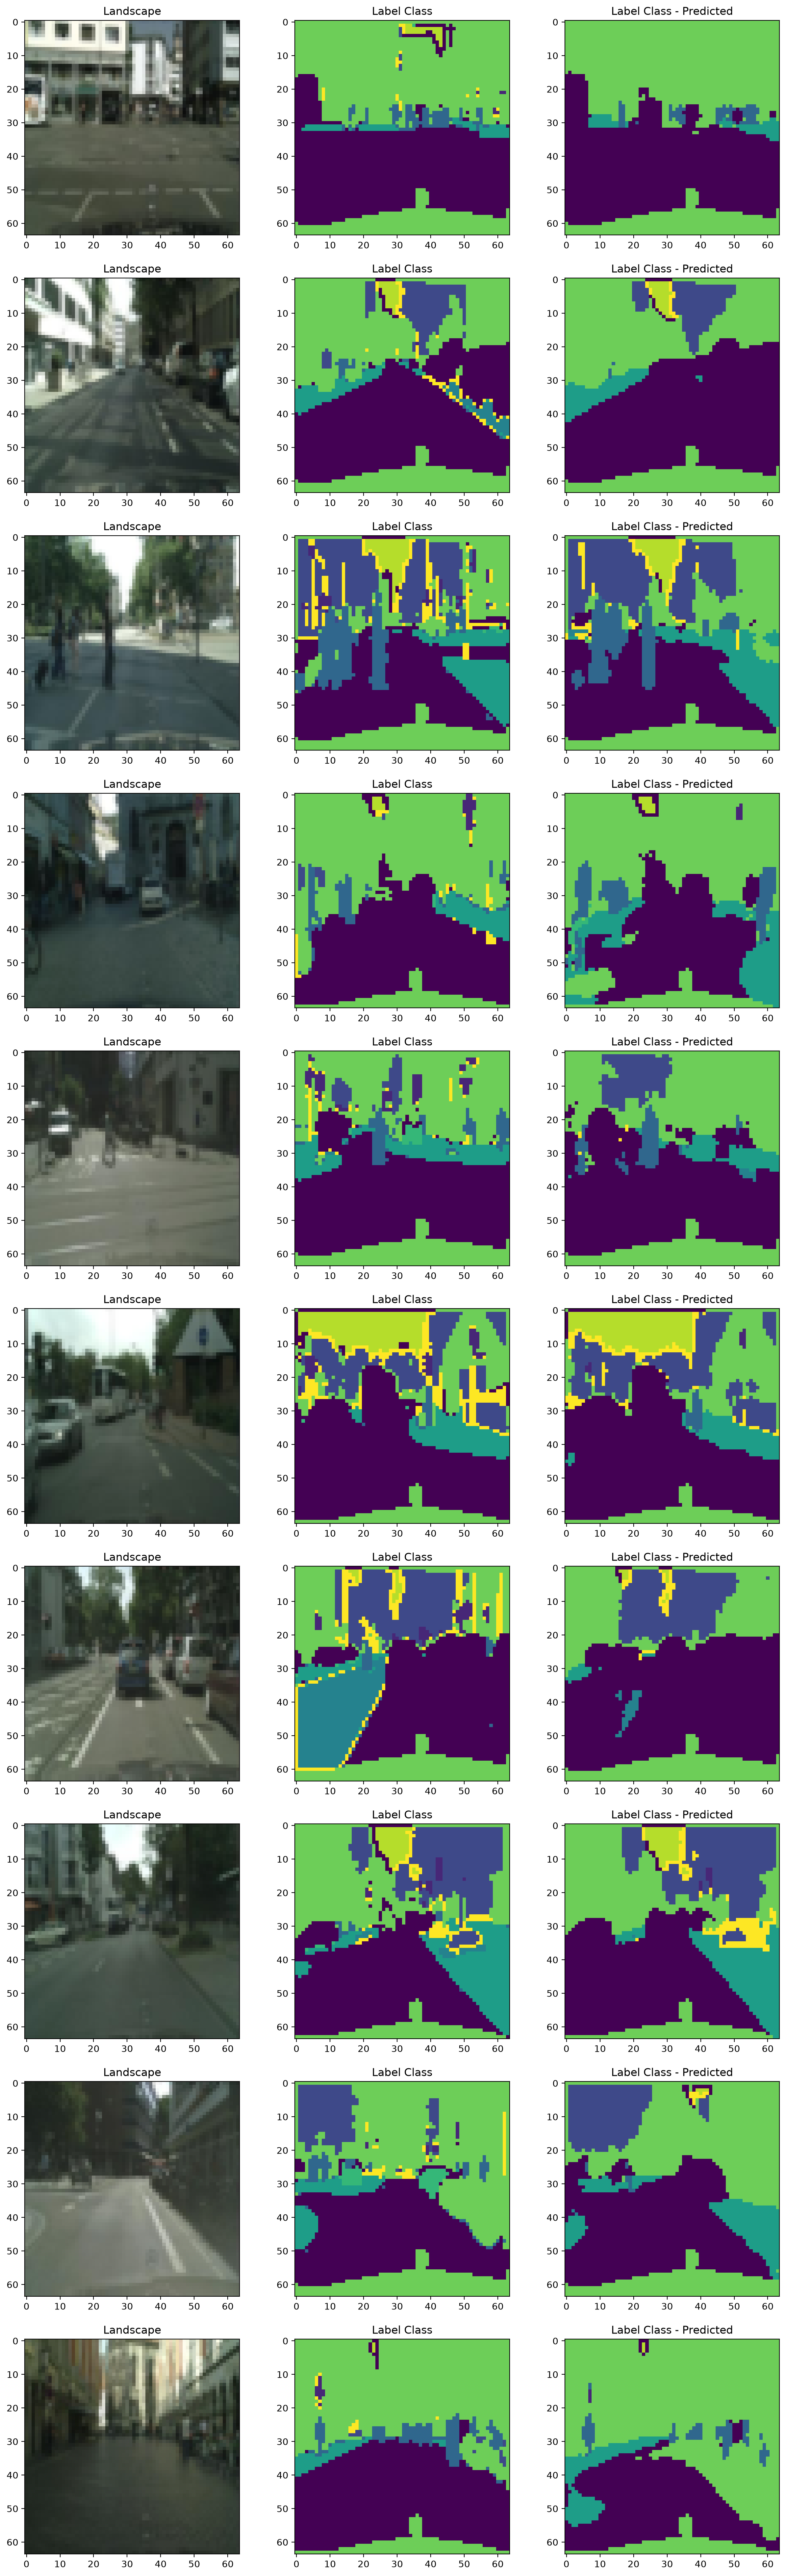

In [23]:
img, labels = next(iter(testloader))
img, labels = img.to(my_unet.device), labels.to(my_unet.device)

my_unet.eval()
with torch.no_grad():
    probs = my_unet.forward(img)

labels_pred = torch.argmax(probs.cpu().detach(), dim=1)

fig, axes = plt.subplots(10, 3, figsize=(3*5, 10*5))

for i in range(10):
    img_plot = np.transpose(img[i,:,:,:].cpu().detach().numpy(), (1, 2, 0))
    img_plot = img_plot / 2 + 0.5
    axes[i, 0].imshow(img_plot)
    axes[i, 0].set_title("Landscape")
    axes[i, 1].imshow(labels[i].cpu().detach().numpy(), vmin=0, vmax=num_classes-1)
    axes[i, 1].set_title("Label Class")
    axes[i, 2].imshow(labels_pred[i].numpy(), vmin=0, vmax=num_classes-1)
    axes[i, 2].set_title("Label Class - Predicted")

**Discussion of the predictions.**

* The U-Net captures very well the **global layout** of the scenes: the road (dark purple) and its boundaries, sidewalks (teal), the buildings / sky region at the top, and the hood of the car at the bottom of every image, which is almost always perfect.
* The predictions are **smoother** than the ground truth. Large regions are segmented accurately, but the thin and small structures (poles, traffic signs, pedestrians, the bright yellow border pixels of the labels) are often lost or merged with the surrounding class. This is partly due to the very low resolution (64x64, so a pole is about 1 pixel wide) and partly because these classes have very few pixels and contribute little to the cross-entropy loss.
* Some errors come from ambiguous classes: e.g. in row 7 the sidewalk on the left is predicted as road, and in rows 4 and 10 parts of the road / sidewalk are confused, since both have very similar textures and colors in such small images.
* The skip connections are what allows the network to produce sharp borders between large regions (e.g. the road/sidewalk edge), since they bring the high-resolution information from the encoder to the decoder.
* Possible improvements: higher input resolution, data augmentation (flips, crops), a class-weighted loss or a Dice loss for the small classes, more epochs with a learning-rate scheduler, and a proper RGB→class mapping (option 1) instead of K-Means over random colors.